# Лабораторная работа №1.1. Разведочный анализ данных (EDA) — классификация

**Цель работы:** выполнить разведочный анализ и предобработку медицинского набора данных, подготовить его для задач классификации (ЛР №3–6).

**Набор данных:** [CDC Diabetes Health Indicators](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) (`csv/cl.csv`) — результаты телефонного опроса BRFSS 2015 (253 680 респондентов).

### Целевой признак
**`Diabetes_012`** — статус диабета: `0` — нет диабета, `1` — преддиабет, `2` — диабет.

### Входные признаки (21)
| Группа | Признаки |
|---|---|
| Кардиометаболические | `HighBP`, `HighChol`, `CholCheck`, `BMI`, `Stroke`, `HeartDiseaseorAttack` |
| Образ жизни | `Smoker`, `PhysActivity`, `Fruits`, `Veggies`, `HvyAlcoholConsump` |
| Здоровье и медицина | `AnyHealthcare`, `NoDocbcCost`, `GenHlth` (1–5), `MentHlth` (0–30), `PhysHlth` (0–30), `DiffWalk` |
| Демография | `Sex`, `Age` (1–13), `Education` (1–6), `Income` (1–8) |

### План
1. Загрузка и проверка структуры данных.
2. Приведение типов, удаление дубликатов.
3. Визуализация распределений, корреляционный анализ.
4. Анализ баланса классов.
5. Сохранение очищенного набора `csv/cl_finished.csv`.

## 1. Импорт библиотек и загрузка данных

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

data = pd.read_csv('csv/cl.csv')
print(f'Размерность: {data.shape}')
data.head()

Размерность: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 2. Структура данных, типы признаков и пропуски

In [2]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  

Пропусков нет, однако все признаки хранятся как `float64`, хотя по смыслу являются целочисленными (бинарными, порядковыми или счётными). Убедимся, что дробных значений нет, и приведём данные к `int`.

In [3]:
non_integer = (data % 1 != 0).sum()
print('Количество нецелых значений по столбцам:', int(non_integer.sum()))

data = data.astype(int)
data['Diabetes_012'].value_counts().rename('count').to_frame()

Количество нецелых значений по столбцам: 0


,count
Diabetes_012,
0,213703
2,35346
1,4631


## 3. Дубликаты и описательная статистика
Анкеты состоят в основном из бинарных/порядковых ответов, поэтому полные дубликаты вероятны. Они искажают распределения и могут попасть одновременно в обучающую и тестовую выборки (утечка данных), поэтому удаляем их.

In [4]:
n_dup = data.duplicated().sum()
print(f'Дубликатов: {n_dup} ({n_dup / len(data):.1%})')

data = data.drop_duplicates().reset_index(drop=True)
print(f'Размерность после очистки: {data.shape}')
print('Распределение классов после удаления дубликатов:')
for cls, label in [(0, 'нет диабета'), (2, 'диабет'), (1, 'преддиабет')]:
    cnt = int((data['Diabetes_012'] == cls).sum())
    print(f'  {cls} ({label}): {cnt} ({cnt / len(data):.2%})')
data.describe().T

Дубликатов: 23899 (9.4%)
Размерность после очистки: (229781, 22)
Распределение классов после удаления дубликатов:
  0 (нет диабета): 190055 (82.71%)
  2 (диабет):       35097 (15.27%)
  1 (преддиабет):    4629 (2.01%)


,count,mean,std,min,25%,50%,75%,max
Diabetes_012,229781.0,0.325627,0.724623,0.0,0.0,0.0,0.0,2.0
HighBP,229781.0,0.454441,0.497921,0.0,0.0,0.0,1.0,1.0
HighChol,229781.0,0.441760,0.496598,0.0,0.0,0.0,1.0,1.0
CholCheck,229781.0,0.959535,0.197047,0.0,1.0,1.0,1.0,1.0
BMI,229781.0,28.685670,6.786360,12.0,24.0,27.0,32.0,98.0
Smoker,229781.0,0.465661,0.498821,0.0,0.0,0.0,1.0,1.0
Stroke,229781.0,0.044756,0.206767,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,229781.0,0.103216,0.304241,0.0,0.0,0.0,0.0,1.0
PhysActivity,229781.0,0.733355,0.442206,0.0,0.0,1.0,1.0,1.0
Fruits,229781.0,0.612966,0.487073,0.0,0.0,1.0,1.0,1.0


## 4. Визуализация распределений и корреляций

### 4.1. Распределение BMI по классам

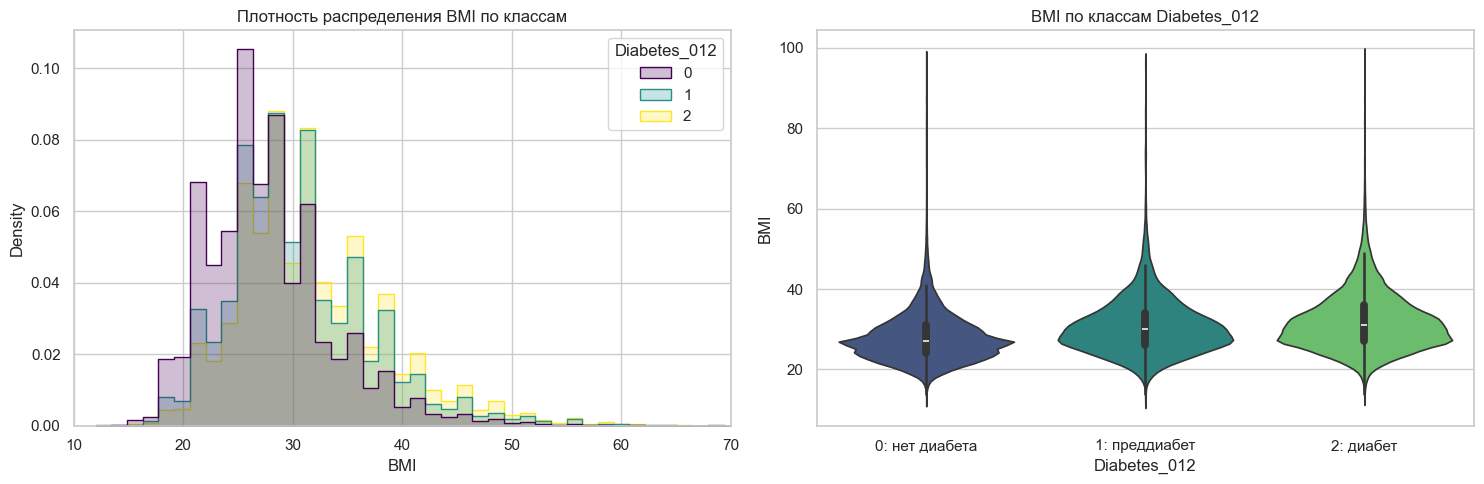

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=data, x='BMI', hue='Diabetes_012', bins=60, stat='density',
             common_norm=False, element='step', palette='viridis', ax=axes[0])
axes[0].set_xlim(10, 70)
axes[0].set_title('Плотность распределения BMI по классам')

sns.violinplot(data=data, x='Diabetes_012', y='BMI', palette='viridis', ax=axes[1])
axes[1].set_xticklabels(['0: нет диабета', '1: преддиабет', '2: диабет'])
axes[1].set_title('BMI по классам Diabetes_012')

plt.tight_layout()
plt.show()

### 4.2. Ранговая корреляция Кендалла
Большинство признаков бинарные или порядковые, поэтому вместо линейной корреляции Пирсона используем ранговый коэффициент **Кендалла** $\tau$.

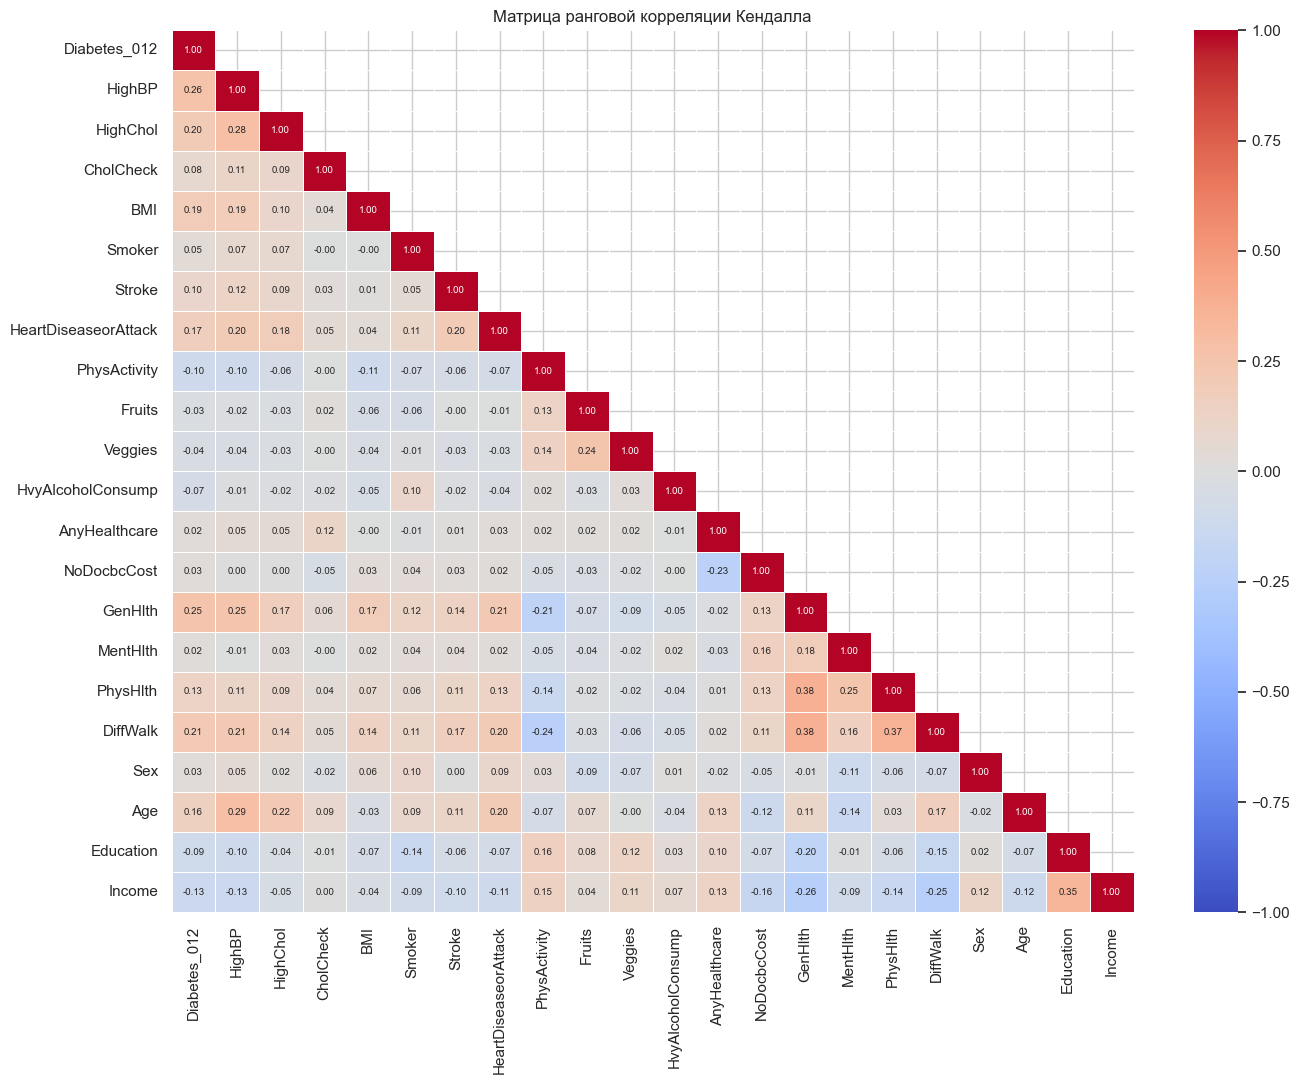

In [6]:
kendall_corr = data.corr(method='kendall')

plt.figure(figsize=(14, 11))
mask = np.triu(np.ones_like(kendall_corr, dtype=bool), k=1)
sns.heatmap(kendall_corr, mask=mask, vmin=-1, vmax=1, cmap='coolwarm',
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5)
plt.title('Матрица ранговой корреляции Кендалла')
plt.tight_layout()
plt.show()

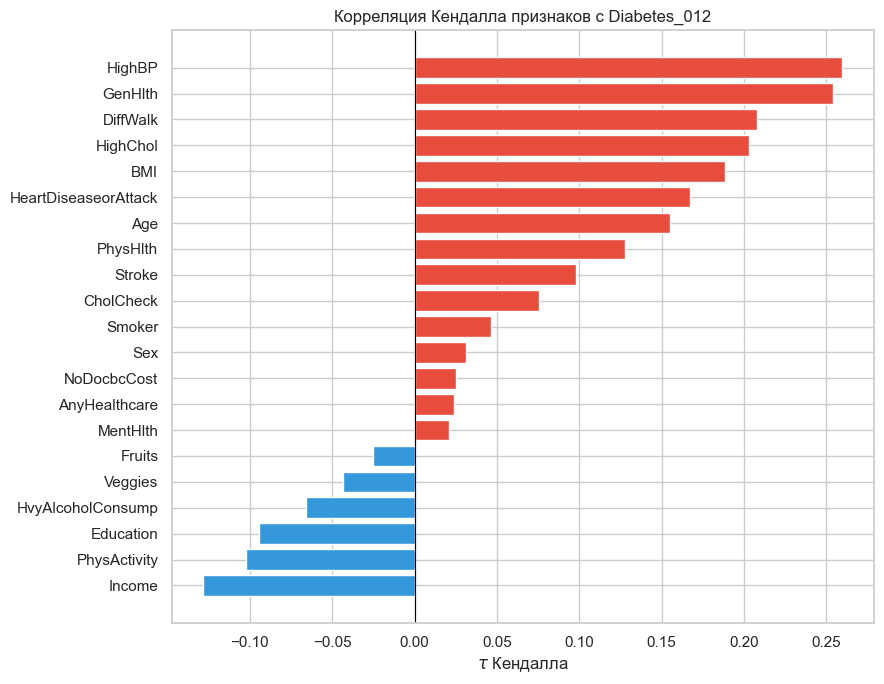

In [7]:
target_corr = kendall_corr['Diabetes_012'].drop('Diabetes_012').sort_values()

plt.figure(figsize=(9, 7))
colors = ['#e74c3c' if v > 0 else '#3498db' for v in target_corr]
plt.barh(target_corr.index, target_corr.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Корреляция Кендалла признаков с Diabetes_012')
plt.xlabel(r'$\tau$ Кендалла')
plt.tight_layout()
plt.show()

### 4.3. Ключевые факторы риска: `GenHlth`, `BMI`, `Age`

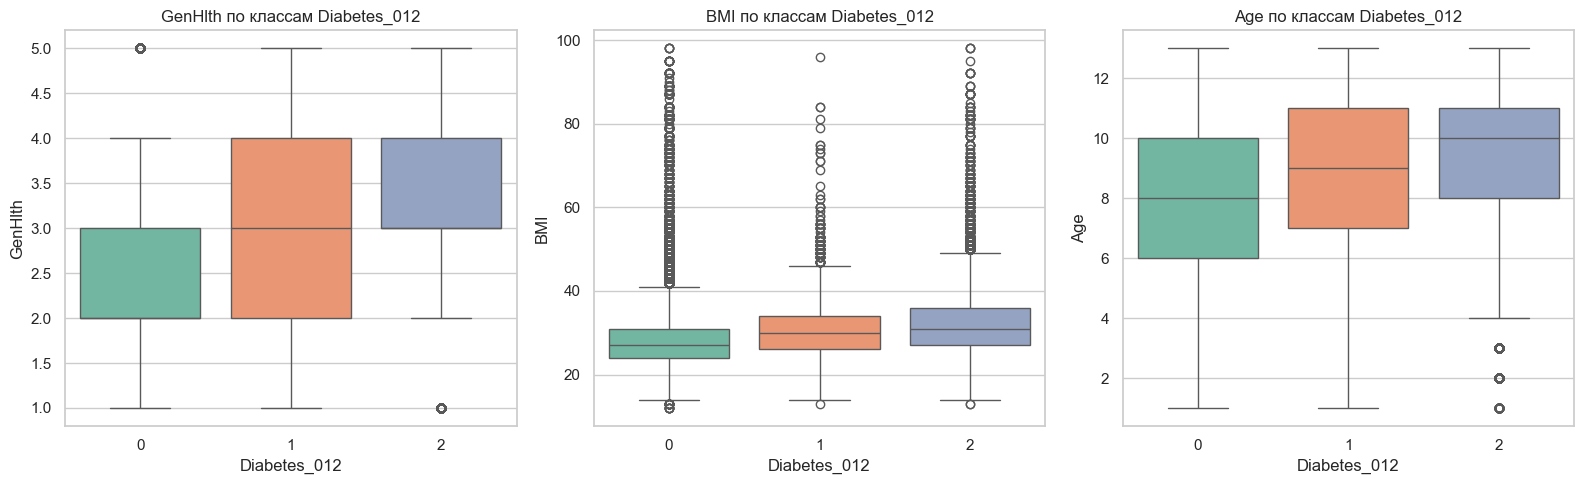

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, feat in zip(axes, ['GenHlth', 'BMI', 'Age']):
    sns.boxplot(x='Diabetes_012', y=feat, data=data, ax=ax, palette='Set2')
    ax.set_title(f'{feat} по классам Diabetes_012')
    ax.set_xlabel('Diabetes_012')
plt.tight_layout()
plt.show()

### 4.4. Доля диабета в зависимости от бинарных факторов

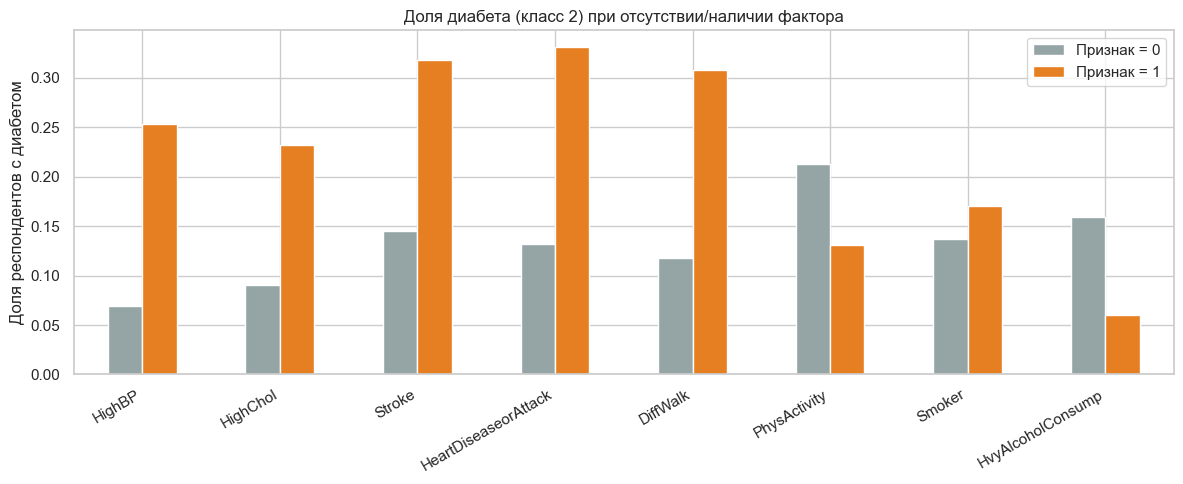

In [9]:
binary_cols = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk',
               'PhysActivity', 'Smoker', 'HvyAlcoholConsump']
rates = pd.DataFrame({
    col: data.groupby(col)['Diabetes_012'].apply(lambda s: (s == 2).mean())
    for col in binary_cols
}).T
rates.columns = ['Признак = 0', 'Признак = 1']

rates.plot(kind='bar', figsize=(12, 5), color=['#95a5a6', '#e67e22'])
plt.ylabel('Доля респондентов с диабетом')
plt.title('Доля диабета (класс 2) при отсутствии/наличии фактора')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 4.5. Баланс классов

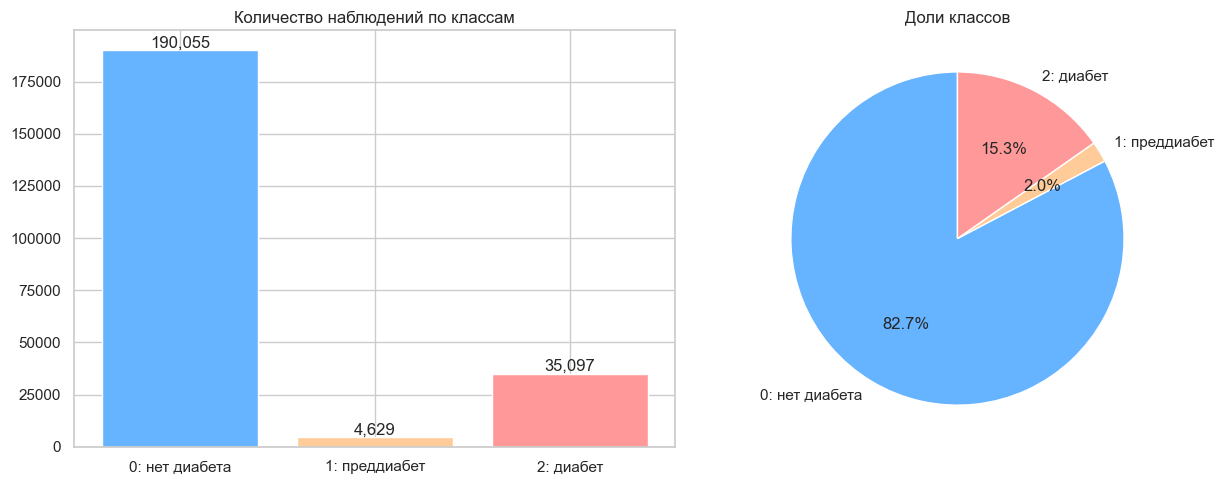

In [10]:
class_counts = data['Diabetes_012'].value_counts().sort_index()
labels = ['0: нет диабета', '1: преддиабет', '2: диабет']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(labels, class_counts.values, color=['#66b3ff', '#ffcc99', '#ff9999'])
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v, f'{v:,}', ha='center', va='bottom')
axes[0].set_title('Количество наблюдений по классам')

axes[1].pie(class_counts, labels=labels, autopct='%1.1f%%', startangle=90,
            colors=['#66b3ff', '#ffcc99', '#ff9999'])
axes[1].set_title('Доли классов')
plt.tight_layout()
plt.show()

## 5. Сохранение предобработанного набора данных

In [11]:
data.to_csv('csv/cl_finished.csv', index=False, sep=';')
print(f'Сохранено в csv/cl_finished.csv, размерность: {data.shape}')

Сохранено в csv/cl_finished.csv, размерность: (229781, 22)


## Выводы
1. **Качество данных.** Пропусков нет; признаки приведены к `int`. Удалено **23 899 дубликатов** (9.4 %), осталось **229 781** наблюдение.
2. **Сильный дисбаланс классов:** `0` — 190 055 (82.7 %), `2` — 35 097 (15.3 %), `1` — 4 629 (2.0 %). Поэтому в следующих работах используются стратифицированное разбиение, `SMOTE` и метрики, устойчивые к дисбалансу ($F_1$-macro, ROC-AUC), а не только Accuracy.
3. **Наиболее связаны с диабетом:** субъективная оценка здоровья `GenHlth` ($\tau \approx 0.28$), высокое давление `HighBP` ($\tau \approx 0.26$), трудности при ходьбе `DiffWalk`, высокий холестерин `HighChol`, `BMI` и возраст `Age` ($\tau \approx 0.18$–$0.21$). Доход `Income` и образование `Education` связаны обратно.
4. Класс «преддиабет» по всем признакам расположен между классами 0 и 2 и сильно с ними перекрывается — это самый трудный для распознавания класс.